# Day 10 - Model Evaluation and Performance Analysis

## Student Performance Prediction System

### Objectives
- Evaluate the optimized Random Forest pipeline.
- Calculate regression performance metrics.
- Analyze actual vs. predicted grades.
- Examine residuals and prediction errors.
- Evaluate performance across student grade groups.
- Document model limitations and findings.

In [2]:

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

print("DAY 10 - MODEL EVALUATION")
print("=" * 50)

# Verify project paths
dataset_path = "../dataset/student-mat.csv"
model_path = "../artifacts/day07_optimized_pipeline.pkl"

print("Dataset exists:", os.path.exists(dataset_path))
print("Optimized model exists:", os.path.exists(model_path))

# Load dataset and optimized pipeline
df = pd.read_csv(dataset_path, sep=";")
optimized_pipeline = joblib.load(model_path)

print("\nDataset shape:", df.shape)
print("Model type:", type(optimized_pipeline))
print("Model pipeline steps:", optimized_pipeline.named_steps.keys())

print("\nEnvironment and artifacts loaded successfully!")


DAY 10 - MODEL EVALUATION
Dataset exists: True
Optimized model exists: True

Dataset shape: (395, 33)
Model type: <class 'sklearn.pipeline.Pipeline'>
Model pipeline steps: dict_keys(['preprocessor', 'model'])

Environment and artifacts loaded successfully!


In [3]:
# Separate features and target
excluded_columns = ["G1", "G2", "G3", "absences"]

X = df.drop(columns=excluded_columns)
y = df["G3"]

# Recreate the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("EVALUATION DATASET PREPARATION")
print("=" * 50)

print("Input features:", X.shape[1])
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nExcluded columns:", excluded_columns)
print("Target variable: G3")

EVALUATION DATASET PREPARATION
Input features: 29
Training samples: 316
Testing samples: 79
Training target: (316,)
Testing target: (79,)

Excluded columns: ['G1', 'G2', 'G3', 'absences']
Target variable: G3


In [4]:
# Generate predictions using the optimized pipeline
y_pred = optimized_pipeline.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

print("OPTIMIZED RANDOM FOREST - MODEL EVALUATION")
print("=" * 50)

for metric, value in zip(evaluation_results["Metric"], evaluation_results["Value"]):
    print(f"{metric}: {value:.4f}")

print("\nPrediction sample:")
print(pd.DataFrame({
    "Actual_G3": y_test.values[:10],
    "Predicted_G3": y_pred[:10].round(2)
}))

OPTIMIZED RANDOM FOREST - MODEL EVALUATION
MAE: 3.2525
RMSE: 4.0798
R2 Score: 0.1882

Prediction sample:
   Actual_G3  Predicted_G3
0         10          5.88
1         12          9.01
2          5          7.93
3         10         10.60
4          9          8.30
5         13         10.52
6         18         12.50
7          6         12.07
8          0         10.70
9         14         11.66


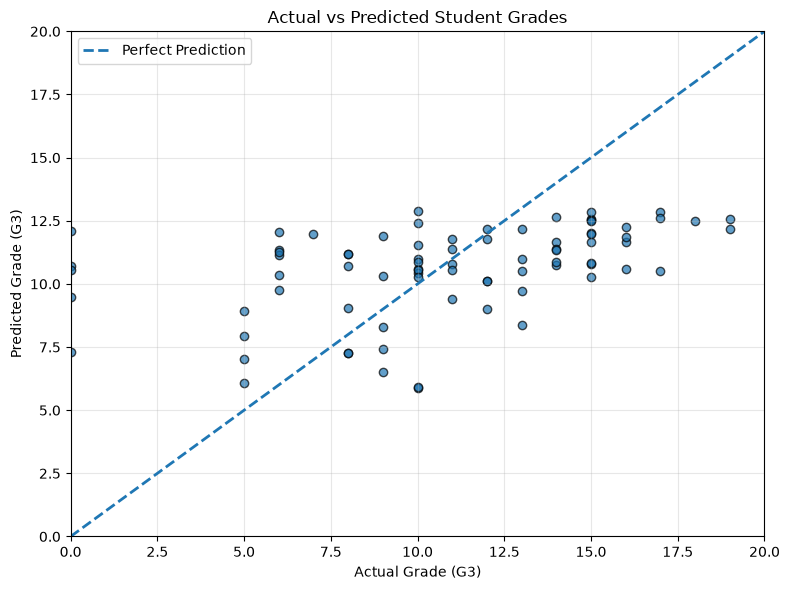

In [5]:
# Actual vs Predicted visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    edgecolor="black"
)

# Perfect prediction reference line
plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Student Grades")
plt.xlabel("Actual Grade (G3)")
plt.ylabel("Predicted Grade (G3)")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

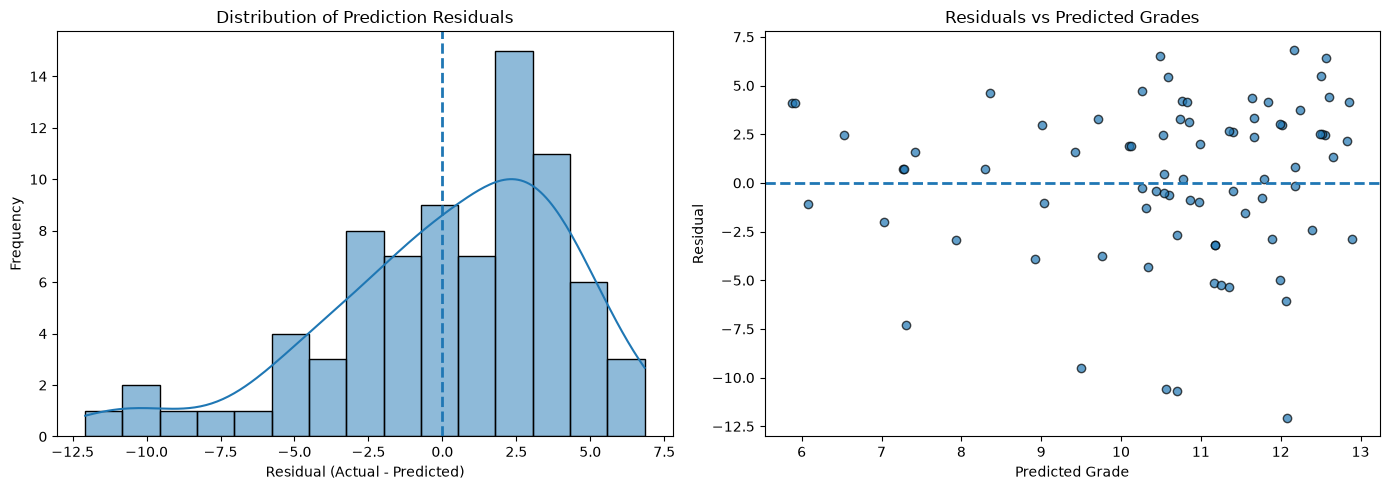

RESIDUAL SUMMARY
Mean residual: 0.1848
Residual standard deviation: 4.0757
Maximum residual: 6.8383
Minimum residual: -12.0771


In [6]:
# Calculate residuals
residuals = y_test.values - y_pred

# Create residual analysis plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residual distribution
sns.histplot(
    residuals,
    bins=15,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(0, linestyle="--", linewidth=2)
axes[0].set_title("Distribution of Prediction Residuals")
axes[0].set_xlabel("Residual (Actual - Predicted)")
axes[0].set_ylabel("Frequency")

# Residuals vs predicted grades
axes[1].scatter(
    y_pred,
    residuals,
    alpha=0.7,
    edgecolor="black"
)
axes[1].axhline(0, linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs Predicted Grades")
axes[1].set_xlabel("Predicted Grade")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

print("RESIDUAL SUMMARY")
print("=" * 40)
print(f"Mean residual: {np.mean(residuals):.4f}")
print(f"Residual standard deviation: {np.std(residuals):.4f}")
print(f"Maximum residual: {np.max(residuals):.4f}")
print(f"Minimum residual: {np.min(residuals):.4f}")

In [7]:
# Create a detailed prediction analysis DataFrame
prediction_analysis = pd.DataFrame({
    "Actual_G3": y_test.values,
    "Predicted_G3": y_pred,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
})

# Define grade categories
grade_bins = [-1, 5, 10, 15, 20]
grade_labels = ["Low (0-5)", "Below Average (6-10)",
                "Above Average (11-15)", "High (16-20)"]

prediction_analysis["Grade_Group"] = pd.cut(
    prediction_analysis["Actual_G3"],
    bins=grade_bins,
    labels=grade_labels
)

# Calculate group-wise performance
group_performance = prediction_analysis.groupby(
    "Grade_Group",
    observed=False
).agg(
    Student_Count=("Actual_G3", "count"),
    Mean_Actual=("Actual_G3", "mean"),
    Mean_Predicted=("Predicted_G3", "mean"),
    MAE=("Absolute_Error", "mean"),
    Mean_Residual=("Residual", "mean")
).round(3)

print("GRADE-WISE MODEL PERFORMANCE")
print("=" * 75)
display(group_performance)

GRADE-WISE MODEL PERFORMANCE


,Student_Count,Mean_Actual,Mean_Predicted,MAE,Mean_Residual
Grade_Group,,,,,
Low (0-5),9,2.222,8.902,6.680,-6.680
Below Average (6-10),29,8.483,10.045,2.556,-1.562
Above Average (11-15),31,13.355,11.144,2.298,2.211
High (16-20),10,17.100,11.951,5.149,5.149


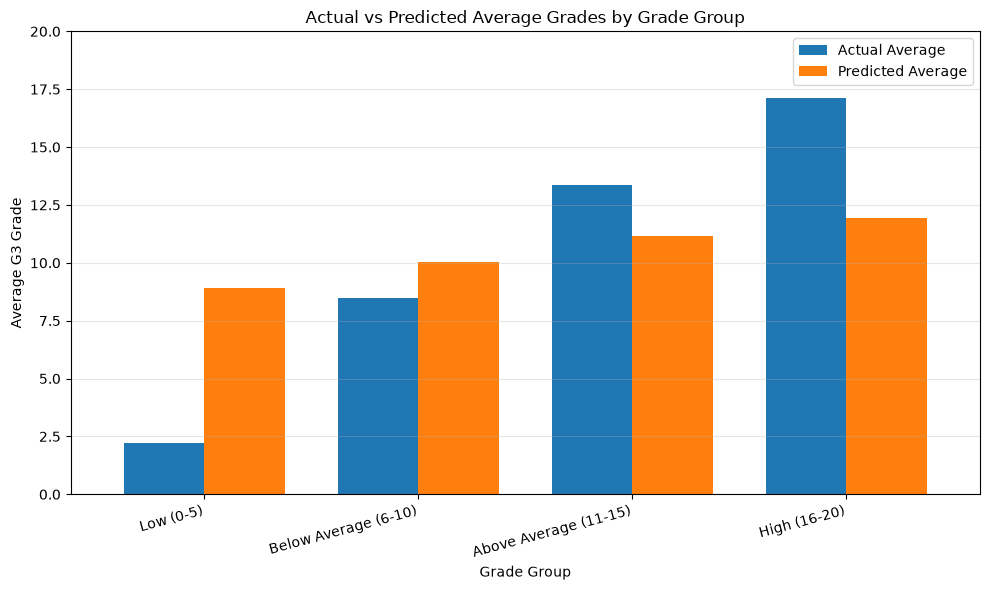

In [8]:
# Prepare data for visualization
plot_data = group_performance[
    ["Mean_Actual", "Mean_Predicted"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Actual vs Predicted Average Grades by Grade Group")
ax.set_xlabel("Grade Group")
ax.set_ylabel("Average G3 Grade")
ax.set_ylim(0, 20)
ax.legend(["Actual Average", "Predicted Average"])
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [9]:
# Sort predictions by absolute error
largest_errors = prediction_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

print("TOP 10 LARGEST PREDICTION ERRORS")
print("=" * 75)

display(
    largest_errors[
        [
            "Actual_G3",
            "Predicted_G3",
            "Residual",
            "Absolute_Error",
            "Grade_Group"
        ]
    ].round(3)
)

print("\nERROR SUMMARY")
print("=" * 40)
print("Total test records:", len(prediction_analysis))
print("Errors greater than 5 grade points:",
      (prediction_analysis["Absolute_Error"] > 5).sum())
print("Errors greater than 3 grade points:",
      (prediction_analysis["Absolute_Error"] > 3).sum())

TOP 10 LARGEST PREDICTION ERRORS


,Actual_G3,Predicted_G3,Residual,Absolute_Error,Grade_Group
24,0,12.077,-12.077,12.077,Low (0-5)
8,0,10.699,-10.699,10.699,Low (0-5)
57,0,10.566,-10.566,10.566,Low (0-5)
19,0,9.497,-9.497,9.497,Low (0-5)
36,0,7.309,-7.309,7.309,Low (0-5)
25,19,12.162,6.838,6.838,High (16-20)
65,17,10.493,6.507,6.507,High (16-20)
73,19,12.573,6.427,6.427,High (16-20)
7,6,12.066,-6.066,6.066,Below Average (6-10)
6,18,12.504,5.496,5.496,High (16-20)



ERROR SUMMARY
Total test records: 79
Errors greater than 5 grade points: 14
Errors greater than 3 grade points: 36


In [10]:
# Create artifacts directory if it does not exist
os.makedirs("../artifacts", exist_ok=True)

# 1. Save overall evaluation metrics
evaluation_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})

evaluation_summary.to_csv(
    "../artifacts/day10_evaluation_metrics.csv",
    index=False
)

# 2. Save all test predictions and errors
prediction_analysis.to_csv(
    "../artifacts/day10_predictions.csv",
    index=False
)

# 3. Save grade-wise performance
group_performance.to_csv(
    "../artifacts/day10_grade_wise_performance.csv"
)

# 4. Save largest prediction errors
largest_errors.to_csv(
    "../artifacts/day10_largest_errors.csv",
    index=False
)

print("DAY 10 ARTIFACTS SAVED")
print("=" * 50)

for filename in [
    "day10_evaluation_metrics.csv",
    "day10_predictions.csv",
    "day10_grade_wise_performance.csv",
    "day10_largest_errors.csv"
]:
    path = "../artifacts/" + filename
    print(f"{filename}: {'Saved' if os.path.exists(path) else 'Not Found'}")

DAY 10 ARTIFACTS SAVED
day10_evaluation_metrics.csv: Saved
day10_predictions.csv: Saved
day10_grade_wise_performance.csv: Saved
day10_largest_errors.csv: Saved


## Day 10 – Model Evaluation and Performance Analysis

### 1. Objective
The objective was to evaluate the optimized Random Forest pipeline, examine prediction errors, analyze performance across different grade groups, and identify the limitations of the student performance prediction system.

### 2. Overall Evaluation Results

| Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 3.2525 |
| Root Mean Squared Error (RMSE) | 4.0798 |
| R² Score | 0.1882 |

The model achieved an MAE of approximately 3.25 grade points. The R² score indicates that the model explains approximately 18.82% of the variation in the test-set grades.

### 3. Actual vs. Predicted Analysis
The actual-versus-predicted plot showed that predictions were concentrated around the middle grade range. The model tended to overpredict lower grades and underpredict higher grades.

### 4. Residual Analysis
The mean residual was 0.1848, with a residual standard deviation of 4.0757. The residual analysis revealed substantial individual prediction errors and a negative tail, indicating some significant overpredictions.

### 5. Grade-wise Performance
The model performed relatively better for students in the middle grade ranges.

- Low (0–5): MAE = 6.680
- Below Average (6–10): MAE = 2.556
- Above Average (11–15): MAE = 2.298
- High (16–20): MAE = 5.149

The model struggled with both low-performing and high-performing students.

### 6. Prediction Error Analysis
Out of 79 test records:
- 14 predictions had an absolute error greater than 5 grade points.
- 36 predictions had an absolute error greater than 3 grade points.
- The maximum absolute prediction error was approximately 12.077 grade points.

### 7. Model Limitations
- The model has limited predictive performance, particularly for extreme grade values.
- The dataset contains only 395 student records.
- The model's predictions may be influenced by the imbalance in grade distribution.
- The system identifies statistical relationships and does not establish causal relationships.
- The evaluation used the same test split that was used during earlier model development and comparison. Therefore, these results should be treated as development-set evaluation rather than an independent final validation.
- Further validation using a separate dataset and additional experiments is required before real-world deployment.

### 8. Conclusion
The optimized Random Forest pipeline was successfully evaluated using regression metrics, residual analysis, grade-wise performance comparisons, and individual prediction error analysis. Although the model demonstrated reasonable performance for middle-grade students, its limitations for extreme grade outcomes highlight opportunities for further improvement.

### 9. Artifacts Generated
- `day10_evaluation_metrics.csv`
- `day10_predictions.csv`
- `day10_grade_wise_performance.csv`
- `day10_largest_errors.csv`

**Day 10 Status:** Completed – Model evaluation and performance analysis successfully documented.